In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\Thesiya M\Downloads\EDA TASK\kc_house_data.csv")

In [26]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,zipcode,lat,long,sqft_living15,sqft_lot15,Sale Year,Property Age,Is Renovated,Price per Square Foot Living,Price per Square Foot Lot
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,98178,47.5112,-122.257,1340,5650,2014,59,No,188.050847,39.274336
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,98125,47.7210,-122.319,1690,7639,2014,63,Yes,209.338521,74.288870
2,5631500400,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,...,98028,47.7379,-122.233,2720,8062,2015,82,No,233.766234,18.000000
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,98136,47.5208,-122.393,1360,5000,2014,49,No,308.163265,120.800000
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,...,98074,47.6168,-122.045,1800,7503,2015,28,No,303.571429,63.118812


In [5]:
df.tail()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287
21612,1523300157,20141015T000000,325000.0,2,0.75,1020,1076,2.0,0,0,...,7,1020,0,2008,0,98144,47.5941,-122.299,1020,1357


In [8]:
df.shape

(21613, 21)

In [9]:
df.dtypes

id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

In [10]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   id                            21613 non-null  int64         
 1   date                          21613 non-null  datetime64[us]
 2   price                         21613 non-null  float64       
 3   bedrooms                      21613 non-null  float64       
 4   bathrooms                     21613 non-null  float64       
 5   sqft_living                   21613 non-null  int64         
 6   sqft_lot                      21613 non-null  int64         
 7   floors                        21613 non-null  float64       
 8   waterfront                    21613 non-null  int64         
 9   view                          21613 non-null  int64         
 10  condition                     21613 non-null  int64         
 11  grade                         21613 non

In [12]:
df.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [13]:
df.isnull().sum().sum()

np.int64(0)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.drop_duplicates()

In [16]:
for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].median())

In [17]:
print("Bedrooms Zero Values:", (df["bedrooms"] == 0).sum())
print("Bathrooms Zero Values:", (df["bathrooms"] == 0).sum())

Bedrooms Zero Values: 13
Bathrooms Zero Values: 10


In [18]:
df.loc[df["bedrooms"] == 0, "bedrooms"] = np.nan
df.loc[df["bathrooms"] == 0, "bathrooms"] = np.nan

df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].median())

In [19]:
df["date"] = pd.to_datetime(df["date"])

In [20]:
df["Sale Year"] = df["date"].dt.year

In [21]:
df["Property Age"] = df["Sale Year"] - df["yr_built"]

In [22]:
df["Is Renovated"] = np.where(df["yr_renovated"] > 0, "Yes", "No")

In [23]:
df["Price per Square Foot Living"] = df["price"] / df["sqft_living"]

In [24]:
df["Price per Square Foot Lot"] = df["price"] / df["sqft_lot"]

In [25]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,zipcode,lat,long,sqft_living15,sqft_lot15,Sale Year,Property Age,Is Renovated,Price per Square Foot Living,Price per Square Foot Lot
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,98178,47.5112,-122.257,1340,5650,2014,59,No,188.050847,39.274336
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,98125,47.7210,-122.319,1690,7639,2014,63,Yes,209.338521,74.288870
2,5631500400,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,...,98028,47.7379,-122.233,2720,8062,2015,82,No,233.766234,18.000000
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,98136,47.5208,-122.393,1360,5000,2014,49,No,308.163265,120.800000
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,...,98074,47.6168,-122.045,1800,7503,2015,28,No,303.571429,63.118812


In [27]:
df["price"].mean()

np.float64(540088.1417665294)

In [28]:
df["price"].median()

np.float64(450000.0)

In [29]:
df["price"].min()

np.float64(75000.0)

In [30]:
df["price"].max()

np.float64(7700000.0)

In [31]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 321950.0
Q3: 645000.0
IQR: 323050.0


In [32]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df["price"] < lower_limit) | (df["price"] > upper_limit)]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

Lower Limit: -162625.0
Upper Limit: 1129575.0
Number of Outliers: 1146


In [33]:
outliers.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,zipcode,lat,long,sqft_living15,sqft_lot15,Sale Year,Property Age,Is Renovated,Price per Square Foot Living,Price per Square Foot Lot
5,7237550310,2014-05-12,1225000.0,4.0,4.50,5420,101930,1.0,0,0,...,98053,47.6561,-122.005,4760,101930,2014,13,No,226.014760,12.018052
21,2524049179,2014-08-26,2000000.0,3.0,2.75,3050,44867,1.0,0,4,...,98040,47.5316,-122.233,4110,20336,2014,46,No,655.737705,44.576192
49,822039084,2015-03-11,1350000.0,3.0,2.50,2753,65005,1.0,1,2,...,98070,47.4041,-122.451,2680,72513,2015,62,No,490.374137,20.767633
69,1802000060,2014-06-12,1325000.0,5.0,2.25,3200,20158,1.0,0,0,...,98004,47.6303,-122.215,3390,20158,2014,49,No,414.062500,65.730727
125,4389200955,2015-03-02,1450000.0,4.0,2.75,2750,17789,1.5,0,0,...,98004,47.6141,-122.212,3060,11275,2015,101,Yes,527.272727,81.511046


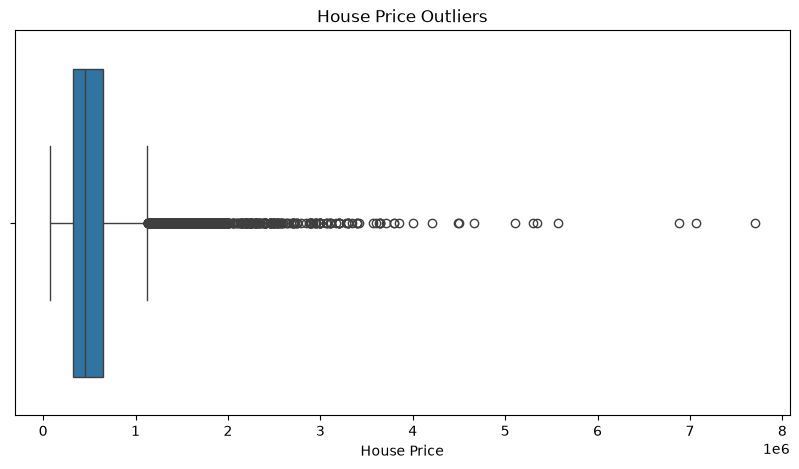

In [34]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["price"])
plt.title("House Price Outliers")
plt.xlabel("House Price")
plt.show()

In [35]:
df.to_csv("cleaned_kc_house_data.csv", index=False)